# Part 3 — Từng bước dự báo PM2.5 bằng ARIMA
**Người thực hiện: Dương · Nhánh `feat/Duong_EDA`**

Giữ mô hình **ARIMA(5,1,1)** đang dùng trong notebook tham khảo, viết lại cách học và đánh giá cho dễ theo dõi. Xem bản tham khảo tại [Part 3 gốc](../Part%203%20-%20PM2.5%20Time%20Series%20Analysis%20with%20ARIMA%20Model.ipynb).

**Bài toán:** cuối mỗi ngày, khi đã có PM2.5 trung bình ngày đó, dự báo trung bình của ngày kế tiếp. Đây là mô phỏng trên dữ liệu lịch sử, không phải dự báo chất lượng không khí hiện tại.

**Luồng bài:** kiểm tra CSV → giữ ngày đủ giờ → chia train/test theo thời gian → hiểu ARIMA và kiểm tra train → fit → dự báo từng ngày → so baseline → xem sai số và giới hạn.

Đọc các ô Markdown trước rồi chạy code ngay dưới. Các số liệu kết luận được sinh từ lần chạy, không chép cố định MAE 16,95 của bài cũ.

## 1. Chuẩn bị: mỗi thư viện làm gì?
`pandas` xử lý bảng và thời gian; `numpy` hỗ trợ tính toán; `matplotlib` vẽ hình; `statsmodels` cung cấp ARIMA, ADF, ACF/PACF và chẩn đoán. Chỉ dùng PM2.5 quá khứ làm đầu vào mô hình, chưa thêm thời tiết.

Kết quả cá nhân ghi vào `Duong/outputs/part3/`; CSV và notebook tham khảo giữ nguyên.

In [1]:
from pathlib import Path
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'Data/hanoi-aqi-weather-data.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook bên trong Hanoi_Air_Analysis.')
OUT = ROOT / 'Duong' / 'outputs' / 'part3'
OUT.mkdir(parents=True, exist_ok=True)
ORDER = (5, 1, 1)  # Giữ cấu hình của bản tham khảo; không chọn lại bằng test.
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'figure.dpi': 110})

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def mae(actual, predicted):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(predicted))))

print('Python', platform.python_version(), '| pandas', pd.__version__, '| ARIMA', ORDER)

Python 3.13.5 | pandas 2.3.2 | ARIMA (5, 1, 1)


## 2. Tạo chuỗi ngày, nối tiếp quy tắc Part 2
Một dòng CSV là một giờ. `resample('D')` gom các giờ thành từng ngày, nhưng chỉ lấy mean chưa đủ: ngày cuối chỉ có một giờ vẫn tạo ra một mean.

Vì vậy kiểm tra thời gian duy nhất, đúng đầu giờ và liên tục; chỉ giữ ngày có **24 giờ và 24 PM2.5 hợp lệ**. Không xóa đỉnh chỉ vì cao. Nếu loại ngày ở giữa làm chuỗi ngày bị đứt, bài dừng để người phân tích quyết định, không tự nối hai ngày không liền nhau như một bước ARIMA.

Đây là khác biệt có chủ đích so với bản tham khảo 367 ngày: bài mới dùng 366 ngày đầy đủ. Do đó kết quả không bắt buộc trùng bài cũ.

In [2]:
raw = pd.read_csv(ROOT / 'Data/hanoi-aqi-weather-data.csv')
raw = raw.drop_duplicates().copy()
raw['Local Time'] = pd.to_datetime(raw['Local Time'], errors='raise')
raw['PM25'] = pd.to_numeric(raw['PM25'], errors='raise')
if raw['Local Time'].isna().any() or raw['Local Time'].duplicated().any():
    raise ValueError('Thời gian thiếu hoặc trùng; cần xem xét trước khi dự báo.')
hourly = raw.sort_values('Local Time').set_index('Local Time')
if not hourly.index.equals(hourly.index.floor('h')):
    raise ValueError('Có thời điểm không đúng đầu giờ.')
expected = pd.date_range(hourly.index.min(), hourly.index.max(), freq='h')
if not hourly.index.equals(expected):
    raise ValueError('Thiếu mốc giờ; chưa có quy tắc xử lý khoảng trống.')
if np.isinf(hourly['PM25'].to_numpy()).any() or hourly['PM25'].lt(0).any():
    raise ValueError('PM2.5 âm hoặc vô hạn.')
audit = hourly.resample('D').agg(hours=('PM25', 'size'), valid=('PM25', 'count'),
                                pm25=('PM25', 'mean'))
complete = audit['hours'].eq(24) & audit['valid'].eq(24)
excluded = audit.loc[~complete].copy()
y = audit.loc[complete, 'pm25'].rename('PM25')
if len(y) < 60 or not y.index.equals(pd.date_range(y.index.min(), y.index.max(), freq='D')):
    raise ValueError('Cần ít nhất 60 ngày liên tục; không tự nội suy hoặc nối tắt ngày thiếu.')
y = y.asfreq('D')
display(excluded.rename_axis('Ngày loại khỏi chuỗi'))
display(pd.DataFrame({'Số giờ CSV': [len(hourly)], 'Số ngày đủ giờ': [len(y)],
                      'Bắt đầu': [y.index.min()], 'Kết thúc': [y.index.max()]}))
display(y.head().to_frame())

,hours,valid,pm25
Ngày loại khỏi chuỗi,,,
2024-03-08,1,1,62.0


,Số giờ CSV,Số ngày đủ giờ,Bắt đầu,Kết thúc
0,8785,366,2023-03-08,2024-03-07


,PM25
Local Time,
2023-03-08,51.208333
2023-03-09,83.125000
2023-03-10,89.416667
2023-03-11,58.416667
2023-03-12,66.333333


## 3. Train và test: học từ quá khứ, kiểm tra ở tương lai
Giữ cách chia **80% đầu để huấn luyện, 20% cuối để kiểm tra**. Không xáo trộn ngày. Train dùng cho ADF, ACF/PACF và chẩn đoán ban đầu; test dùng đánh giá dự báo.

`cutoff = int(len(y) * 0.8)` lấy phần nguyên: 366 ngày tạo 292 train và 74 test. Biểu đồ dưới chỉ minh họa phạm vi, không dùng test để chọn tham số.

**Lưu ý giới hạn:** cấu hình (5,1,1) kế thừa bài trước và dữ liệu này đã từng được khám phá. Đây là tái đánh giá mang tính học tập, không phải một tập test mới hoàn toàn chưa từng được xem.

,Nhóm,Số ngày,Từ,Đến
0,Train,292,2023-03-08,2023-12-24
1,Test,74,2023-12-25,2024-03-07


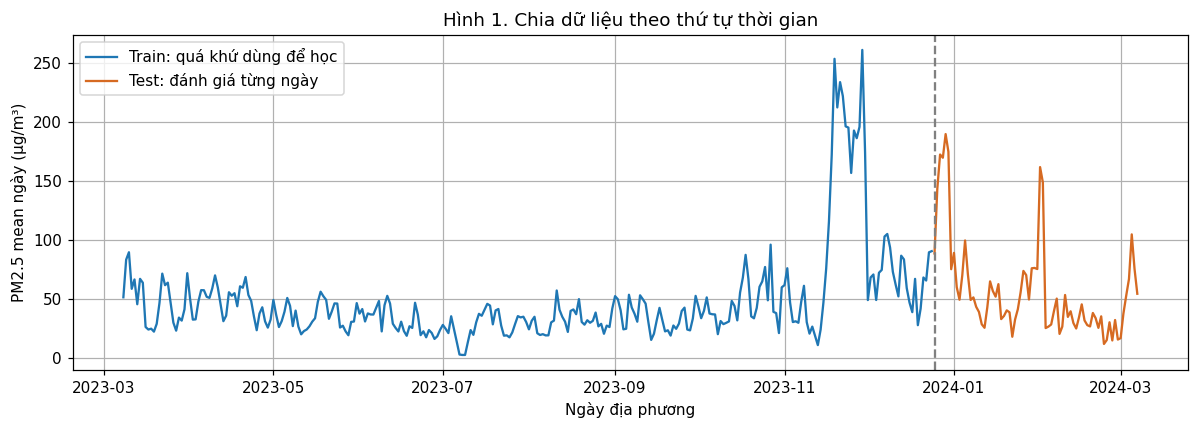

In [3]:
cutoff = int(len(y) * 0.8)
train, test = y.iloc[:cutoff].copy(), y.iloc[cutoff:].copy()
display(pd.DataFrame({'Nhóm': ['Train', 'Test'], 'Số ngày': [len(train), len(test)],
                      'Từ': [train.index.min(), test.index.min()],
                      'Đến': [train.index.max(), test.index.max()]}))
fig, ax = plt.subplots()
ax.plot(train, label='Train: quá khứ dùng để học')
ax.plot(test, label='Test: đánh giá từng ngày', color='#d66a22')
ax.axvline(test.index[0], color='gray', linestyle='--')
ax.set(xlabel='Ngày địa phương', ylabel='PM2.5 mean ngày (µg/m³)',
       title='Hình 1. Chia dữ liệu theo thứ tự thời gian')
ax.legend()
save_figure(fig, '01_train_test')

## 4. ARIMA(5,1,1) nghĩa là gì?

| Thành phần | Trong bài này | Cách hiểu |
|---|---|---|
| AR — p | 5 | Mô hình dùng cấu trúc phụ thuộc vào 5 độ trễ của chuỗi sau sai phân |
| I — d | 1 | Lấy sai phân một lần: Δyₜ = yₜ − yₜ₋₁ |
| MA — q | 1 | Mô hình hóa thêm sai số nhiễu trễ một bước |

Vì dữ liệu theo ngày, một lag là **một ngày**. Ví dụ hôm qua 40, hôm nay 46 thì sai phân hôm nay bằng 6. MA ở đây là thành phần sai số trong mô hình, không phải đường trung bình trượt 7 ngày của EDA.

Ta truyền chuỗi nồng độ gốc và `order=(5,1,1)` vào statsmodels. Thư viện xử lý sai phân và đưa dự báo về thang nồng độ; không truyền chuỗi đã sai phân rồi lại đặt d=1.

Giữ cấu hình này để hiểu và đối chiếu mô hình cũ; bài không khẳng định đây là bộ tham số tối ưu. Không lặp grid search MAE trên chính train rồi gọi đó là đánh giá ngoài mẫu.

### 4.1. ADF: nhìn chuỗi train trước và sau sai phân
ADF có giả thuyết H0 là có nghiệm đơn vị. Với ngưỡng 5%, p < 0,05 là bằng chứng bác bỏ H0 theo kiểm định; p ≥ 0,05 nghĩa là chưa đủ bằng chứng bác bỏ, không chứng minh chắc chắn chuỗi không dừng.

Tính dừng nói về sự ổn định của các đặc trưng thống kê theo thời gian, không có nghĩa đường dữ liệu phải phẳng. ADF là công cụ tham khảo có giả định và giới hạn, không tự chứng minh mô hình dự báo tốt. Trong bài này d=1 được giữ theo mô hình gốc, không tự thay đổi từ kết quả test.

C:\Users\huyhi\AppData\Local\Temp\ipykernel_10672\2634699745.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, pvalue, usedlag, nobs, critical, *_ = adfuller(series, autolag='AIC')
C:\Users\huyhi\AppData\Local\Temp\ipykernel_10672\2634699745.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, pvalue, usedlag, nobs, critical, *_ = adfuller(series, a

,ADF,p-value,Lag kiểm định,Số mẫu kiểm định,Đọc tại 5%
Chuỗi,,,,,
Train gốc,-2.645686,8.391758e-02,13,278,Chưa bác bỏ H0
Sai phân train một lần,-6.256698,4.321459e-08,12,278,Bác bỏ H0


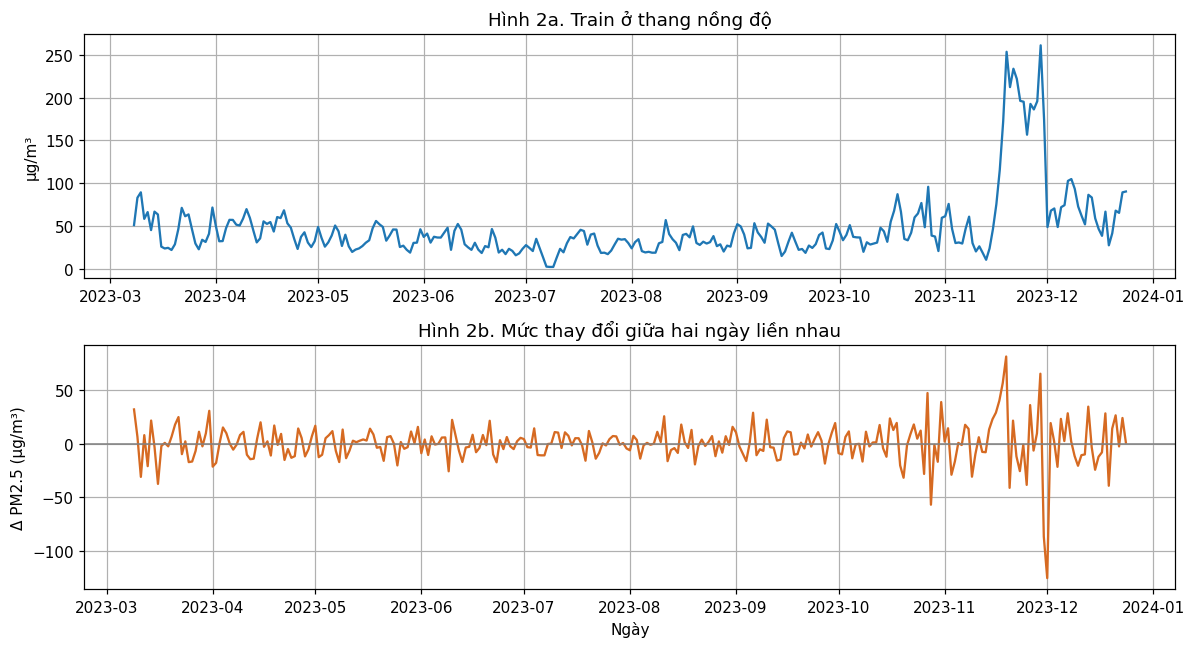

In [4]:
adf_rows = []
for name, series in [('Train gốc', train), ('Sai phân train một lần', train.diff().dropna())]:
    statistic, pvalue, usedlag, nobs, critical, *_ = adfuller(series, autolag='AIC')
    adf_rows.append({'Chuỗi': name, 'ADF': statistic, 'p-value': pvalue,
                     'Lag kiểm định': usedlag, 'Số mẫu kiểm định': nobs,
                     'Đọc tại 5%': 'Bác bỏ H0' if pvalue < .05 else 'Chưa bác bỏ H0'})
adf_table = pd.DataFrame(adf_rows).set_index('Chuỗi')
display(adf_table)
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(train)
axes[0].set(title='Hình 2a. Train ở thang nồng độ', ylabel='µg/m³')
axes[1].plot(train.diff().dropna(), color='#d66a22')
axes[1].axhline(0, color='gray', linewidth=1)
axes[1].set(title='Hình 2b. Mức thay đổi giữa hai ngày liền nhau', ylabel='Δ PM2.5 (µg/m³)', xlabel='Ngày')
save_figure(fig, '02_differencing')

### 4.2. ACF và PACF: chuỗi còn nhớ các ngày trước ra sao?
ACF xem tương quan với giá trị trễ; PACF xem liên hệ tuyến tính riêng phần sau khi tính đến các độ trễ trung gian. Hình dưới dùng **sai phân của train**, phù hợp với phần AR/MA khi d=1.

Các dải là khoảng tham khảo xấp xỉ của hệ số. Một vài cột vượt dải không đủ chứng minh chọn đúng p/q hoặc kết luận không có mùa vụ. Ta giữ (5,1,1), dùng hình để hiểu cấu trúc, không chọn lại bằng test.

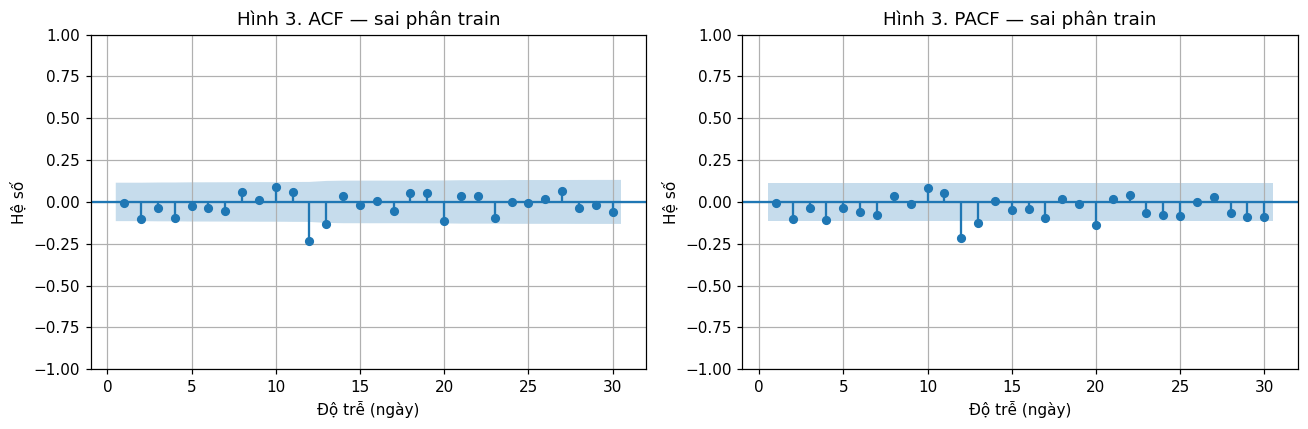

In [5]:
difference = train.diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(difference, lags=30, zero=False, ax=axes[0])
plot_pacf(difference, lags=30, zero=False, method='ywm', ax=axes[1])
for ax, name in zip(axes, ['ACF', 'PACF']):
    ax.set(title=f'Hình 3. {name} — sai phân train', xlabel='Độ trễ (ngày)', ylabel='Hệ số')
save_figure(fig, '03_acf_pacf')

## 5. Fit trên train và xem phần dư
`fit()` ước lượng các hệ số từ lịch sử. `order` chỉ cấu trúc mô hình; hệ số số học là thứ mô hình học từ dữ liệu.

Phần dư là quan sát trừ giá trị khớp trong train, khác sai số dự báo ngoài mẫu ở test. Ta bỏ đoạn khởi tạo theo burn-in và số lag để hạn chế ảnh hưởng khởi tạo khi chẩn đoán.

Hình phần dư và ACF giúp tìm cấu trúc còn sót. Ljung–Box ở lag 10 và 20 kiểm tra tự tương quan chung tới lag đó, điều chỉnh 6 bậc tự do AR/MA (p+q). p nhỏ gợi ý còn cấu trúc; p lớn chưa chứng minh phần dư hoàn hảo hoặc dự báo đáng tin.

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                   PM25   No. Observations:                  292
Model:                 ARIMA(5, 1, 1)   Log Likelihood               -1249.260
Date:                Sat, 28 Nov 2026   AIC                           2512.520
Time:                        18:42:12   BIC                           2538.233
Sample:                    03-08-2023   HQIC                          2522.820
                         - 12-24-2023                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9248      0.045     20.447      0.000       0.836       1.013
ar.L2         -0.1014      0.044     -2.316      0.021      -0.187      -0.016
ar.L3          0.0595      0.070      0.848      0.397      -0.078       0.197
ar.L4         -0.0740      0.070     -1.052      0.293      -0.212       0.064
ar.L5          0.0550      0.058      0.952      0.341      -0.058       0.168
ma.L1         -0.9778      0.023    -42.217      0.000      -1.023      -0.932
sigma2       312.7279     14.246     21.952      0.000     284.807     340.649
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):               958.27
Prob(Q):                              0.99   Prob(JB):                         0.00
Heteroskedasticity (H):               4.77   Skew:                             0.11
Prob(H) (two-sided):                  0.00   Kurtosis:                        11.89
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

,lb_stat,lb_pvalue
Lag (ngày),,
10,3.979531,0.408783
20,32.547421,0.003347


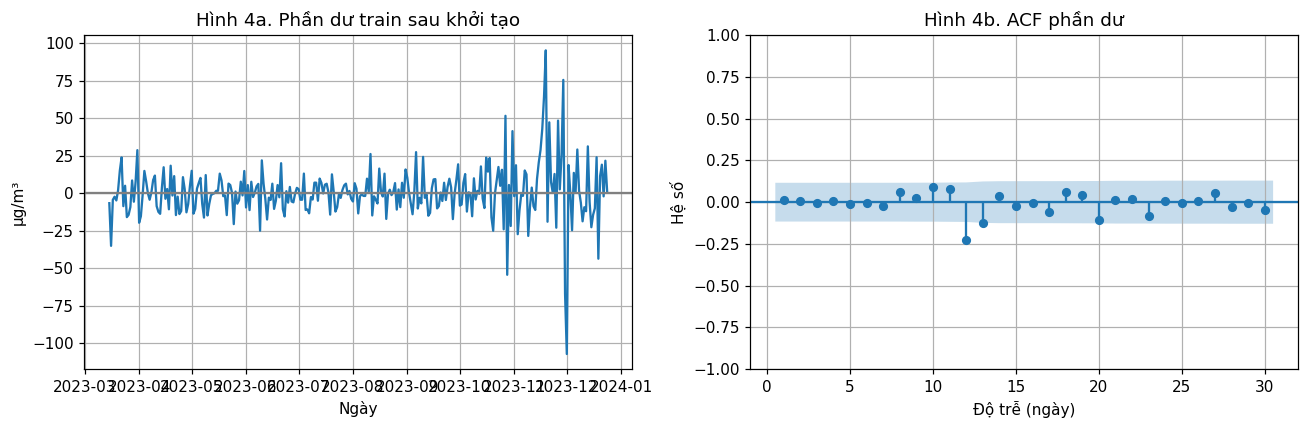

In [6]:
fit_warnings = []
def fit_arima(history, stage):
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        fitted = ARIMA(history, order=ORDER).fit()
    for warning in captured:
        fit_warnings.append({'stage': stage, 'category': warning.category.__name__,
                             'message': str(warning.message)})
    converged = bool(fitted.mle_retvals.get('converged', True))
    if not converged:
        print(f'CHÚ Ý: tối ưu chưa hội tụ ở {stage}; xem bảng hội tụ và warnings.json.')
    return fitted, converged

initial_fit, initial_converged = fit_arima(train, 'train')
display(initial_fit.summary())
burn = max(int(initial_fit.loglikelihood_burn), sum(ORDER))
residuals = initial_fit.resid.iloc[burn:]
ljung = acorr_ljungbox(residuals, lags=[10, 20], model_df=ORDER[0]+ORDER[2], return_df=True)
display(ljung.rename_axis('Lag (ngày)'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(residuals)
axes[0].axhline(0, color='gray')
axes[0].set(title='Hình 4a. Phần dư train sau khởi tạo', xlabel='Ngày', ylabel='µg/m³')
plot_acf(residuals, lags=30, zero=False, ax=axes[1])
axes[1].set(title='Hình 4b. ACF phần dư', xlabel='Độ trễ (ngày)', ylabel='Hệ số')
save_figure(fig, '04_residuals')

## 6. Hai baseline: mô hình phải hơn được cách đoán đơn giản nào?
**Baseline mean:** mọi ngày test đều dự báo bằng mean train ban đầu. Không tính mean của cả bộ dữ liệu vì như vậy sẽ dùng tương lai.

**Baseline persistence:** ngày mai bằng hôm nay. Khi đến một ngày test, ngày test trước đã được quan sát, nên có thể dùng giá trị thật của ngày trước đó.

Cả hai sẽ được chấm trên **cùng 74 ngày test** như ARIMA. Không đem MAE train của baseline so với MAE test của ARIMA như kết luận cũ.

In [7]:
predictions = pd.DataFrame(index=test.index)
predictions['actual'] = test
predictions['mean_train'] = float(train.mean())
predictions['persistence'] = y.shift(1).reindex(test.index)
display(predictions.head())

,actual,mean_train,persistence
Local Time,,,
2023-12-25,88.395833,47.50524,90.382083
2023-12-26,143.104167,47.50524,88.395833
2023-12-27,172.305417,47.50524,143.104167
2023-12-28,169.569583,47.50524,172.305417
2023-12-29,189.652917,47.50524,169.569583


## 7. Walk-forward: dự báo rồi mới được xem đáp án
Với từng ngày test t:

1. Fit ARIMA trên lịch sử kết thúc ở ngày t−1.
2. Dự báo đúng một ngày t và lưu dự báo, khoảng dự báo.
3. Sau đó mới thêm giá trị thật của t vào lịch sử để chuẩn bị dự báo t+1.

Ví dụ nếu test bắt đầu ngày 25, lần đầu chỉ học đến hết ngày 24. Khi biết ngày 25 thực tế, mới được dùng nó để dự báo ngày 26. Mỗi vòng fit lại tham số trên lịch sử mở rộng, giữ nguyên order (5,1,1).

Đây không phải dự báo đồng thời toàn bộ 74 ngày chỉ từ mốc cuối train. Dùng thực tế hôm trước trong vòng sau là đúng với giả định cập nhật mỗi ngày. Vòng lặp có thể mất vài phút; dòng tiến độ cho biết đang chạy đến đâu.

In [8]:
history = train.copy()
forecast_rows = []
for step, (date, observed) in enumerate(test.items(), start=1):
    assert history.index.max() == date - pd.Timedelta(days=1)
    fitted, converged = fit_arima(history, str(date.date()))
    forecast = fitted.get_forecast(steps=1)
    predicted = float(forecast.predicted_mean.iloc[0])
    lower, upper = map(float, forecast.conf_int(alpha=.05).iloc[0])
    forecast_rows.append({'date': date, 'arima': predicted, 'lower95': lower,
                          'upper95': upper, 'converged': converged,
                          'history_end': history.index.max(), 'history_days': len(history)})
    # Quan sát hôm nay chỉ được thêm sau khi đã lưu dự báo hôm nay.
    history = pd.concat([history, pd.Series([observed], index=pd.DatetimeIndex([date]), name='PM25')]).asfreq('D')
    if step == 1 or step % 10 == 0 or step == len(test):
        print(f'Đã dự báo {step}/{len(test)} ngày', flush=True)
walk = pd.DataFrame(forecast_rows).set_index('date')
predictions = predictions.join(walk)
display(predictions.head())

Đã dự báo 1/74 ngày


Đã dự báo 10/74 ngày


Đã dự báo 20/74 ngày


Đã dự báo 30/74 ngày


Đã dự báo 40/74 ngày


Đã dự báo 50/74 ngày


Đã dự báo 60/74 ngày


Đã dự báo 70/74 ngày


Đã dự báo 74/74 ngày


,actual,mean_train,persistence,arima,lower95,upper95,converged,history_end,history_days
Local Time,,,,,,,,,
2023-12-25,88.395833,47.50524,90.382083,86.267873,51.607647,120.928099,True,2023-12-24,292
2023-12-26,143.104167,47.50524,88.395833,87.468877,52.866850,122.070904,True,2023-12-25,293
2023-12-27,172.305417,47.50524,143.104167,138.088110,102.971923,173.204297,True,2023-12-26,294
2023-12-28,169.569583,47.50524,172.305417,162.168749,126.895252,197.442246,True,2023-12-27,295
2023-12-29,189.652917,47.50524,169.569583,160.733757,125.510225,195.957290,True,2023-12-28,296


## 8. Đọc kết quả: MAE, hình dự báo và sai số
**MAE = trung bình |thực tế − dự báo|**. Ví dụ thực tế [30, 50], dự báo [35, 40] thì MAE = (5+10)/2 = 7,5 µg/m³. MAE thấp hơn là tốt hơn trên cùng tập đánh giá; không có nghĩa mọi ngày sai đúng bằng MAE.

Mức cải thiện so persistence = `(MAE persistence − MAE ARIMA) / MAE persistence × 100%`. Âm nghĩa là ARIMA kém hơn baseline này. Không làm tròn dự báo trước khi chấm.

Hình 5 cho thấy các đường cùng ngày và khoảng dự báo 95% theo giả định mô hình. Dải này không phải cam kết bao phủ 95% thực tế; bài đo thêm tỷ lệ thực tế nằm trong dải. ARIMA có thể cho cận dưới âm; ta giữ kết quả để thấy hạn chế của mô hình, không âm thầm cắt về 0.

,MAE (µg/m³)
Phương pháp,
Mean train,27.562
Persistence,17.404
"ARIMA(5,1,1)",16.904


**Kết quả:** MAE ARIMA **16.904 µg/m³**, persistence **17.404 µg/m³**. Cải thiện so persistence **+2.88%**. Bao phủ khoảng dự báo trên test **93.2%**; **0/74** lần fit test chưa hội tụ.

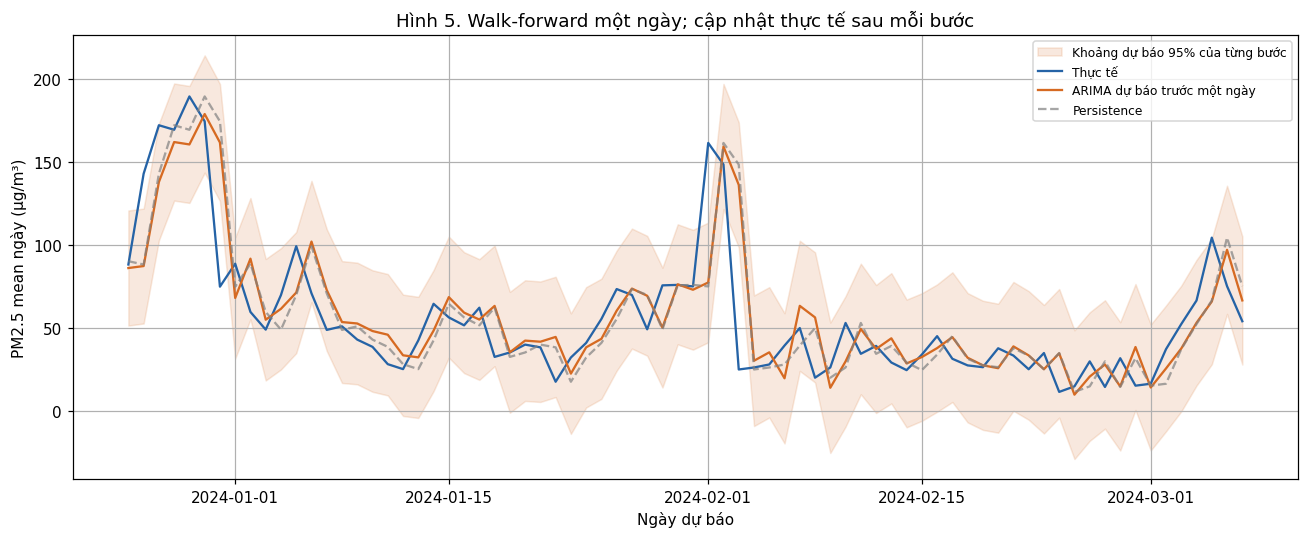

In [9]:
scores = pd.DataFrame([
    {'Phương pháp': label, 'MAE (µg/m³)': mae(test, predictions[column])}
    for column, label in [('mean_train', 'Mean train'), ('persistence', 'Persistence'), ('arima', 'ARIMA(5,1,1)')]
]).set_index('Phương pháp')
arima_mae = scores.loc['ARIMA(5,1,1)', 'MAE (µg/m³)']
persistence_mae = scores.loc['Persistence', 'MAE (µg/m³)']
improvement = 100 * (persistence_mae - arima_mae) / persistence_mae if persistence_mae else None
coverage = float(((test >= predictions.lower95) & (test <= predictions.upper95)).mean())
display(scores.round(3))
display(Markdown(f'**Kết quả:** MAE ARIMA **{arima_mae:.3f} µg/m³**, persistence **{persistence_mae:.3f} µg/m³**. '
                 + (f'Cải thiện so persistence **{improvement:+.2f}%**. ' if improvement is not None else 'Baseline MAE bằng 0; không tính tỷ lệ cải thiện. ')
                 + f'Bao phủ khoảng dự báo trên test **{coverage:.1%}**; '
                 f'**{int((~predictions.converged).sum())}/{len(test)}** lần fit test chưa hội tụ.'))
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(predictions.index, predictions.lower95, predictions.upper95,
                alpha=.15, color='#d66a22', label='Khoảng dự báo 95% của từng bước')
ax.plot(test, label='Thực tế', color='#2563a6')
ax.plot(predictions.arima, label='ARIMA dự báo trước một ngày', color='#d66a22')
ax.plot(predictions.persistence, label='Persistence', color='gray', linestyle='--', alpha=.7)
ax.set(title='Hình 5. Walk-forward một ngày; cập nhật thực tế sau mỗi bước',
       xlabel='Ngày dự báo', ylabel='PM2.5 mean ngày (µg/m³)')
ax.legend(fontsize=8)
save_figure(fig, '05_walk_forward')

### 8.1. Những ngày nào mô hình sai nhiều?
Quy ước **sai số = thực tế − dự báo**. Dương là dự báo thấp hơn thực tế; âm là dự báo cao hơn. Bảng xếp các ngày theo sai số tuyệt đối để không chỉ nhìn đường dự báo có vẻ giống thực tế.

Hình 6 là sai số trên test của các dự báo một ngày, khác phần dư train ở Hình 4. Các đỉnh sai số gợi ý ngày khó dự báo, chưa cho biết nguyên nhân ô nhiễm. Muốn khẳng định dự báo trễ cần kiểm tra thêm, không chỉ nhìn hai đường gần nhau.

,actual,arima,persistence,error,absolute_error
Local Time,,,,,
2024-02-03,25.145,136.377,148.639,-111.232,111.232
2023-12-31,75.042,161.903,174.652,-86.861,86.861
2024-02-01,161.647,77.575,75.200,84.072,84.072
2023-12-26,143.104,87.469,88.396,55.635,55.635
2024-03-05,104.585,66.079,66.708,38.505,38.505


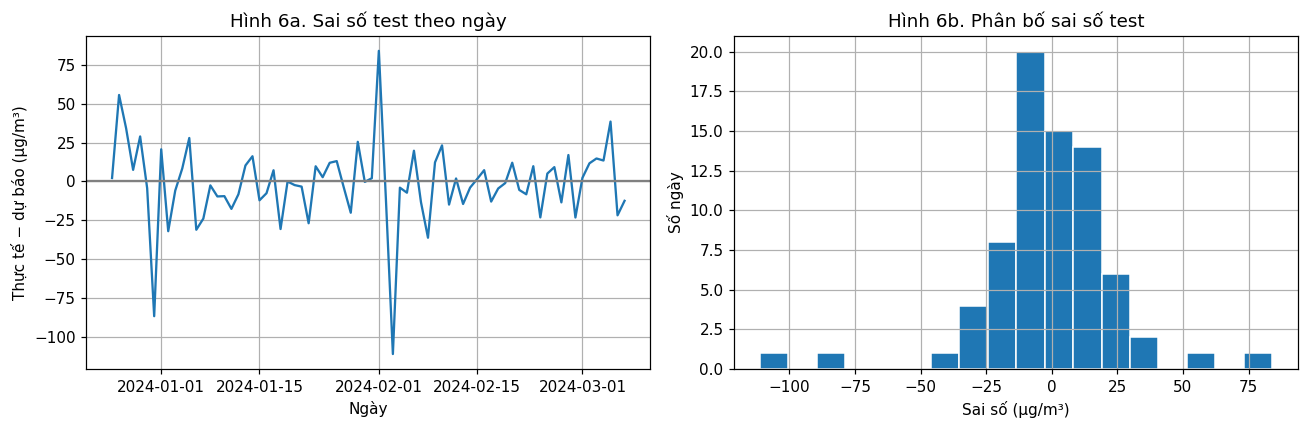

In [10]:
predictions['error'] = predictions.actual - predictions.arima
predictions['absolute_error'] = predictions.error.abs()
display(predictions.nlargest(5, 'absolute_error')[['actual', 'arima', 'persistence', 'error', 'absolute_error']].round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(predictions.error)
axes[0].axhline(0, color='gray')
axes[0].set(title='Hình 6a. Sai số test theo ngày', xlabel='Ngày', ylabel='Thực tế − dự báo (µg/m³)')
axes[1].hist(predictions.error, bins='auto', edgecolor='white')
axes[1].set(title='Hình 6b. Phân bố sai số test', xlabel='Sai số (µg/m³)', ylabel='Số ngày')
save_figure(fig, '06_test_errors')

## 9. Kiểm tra và lưu: người khác đối chiếu được gì?
Kiểm tra ngày dự báo khớp test, không có NaN/vô hạn, lịch sử kết thúc trước ngày dự báo một ngày và số mẫu tăng đúng một sau mỗi vòng. Baseline persistence cũng phải đúng bằng quan sát ngày trước.

Các kiểm tra này xác nhận tính nhất quán của phép đánh giá, không chứng minh ARIMA luôn dự báo tốt. Cảnh báo tối ưu được lưu thay vì bỏ qua. Nếu có lần chưa hội tụ, các MAE vẫn là đầu ra của lần chạy nhưng cần đọc cùng hạn chế này.

In [11]:
assert train.index.max() < test.index.min()
assert predictions.index.equals(test.index)
numeric_columns = ['actual', 'arima', 'persistence', 'mean_train', 'lower95', 'upper95']
assert np.isfinite(predictions[numeric_columns].to_numpy()).all()
assert predictions.history_end.eq(predictions.index - pd.Timedelta(days=1)).all()
assert predictions.history_days.tolist() == list(range(len(train), len(train)+len(test)))
assert np.allclose(predictions.persistence, y.shift(1).loc[test.index])
assert predictions.lower95.le(predictions.upper95).all()
assert all(audit.loc[y.index, 'hours'].eq(24))
predictions.to_csv(OUT / 'predictions.csv', index_label='date')
scores.to_csv(OUT / 'metrics.csv')
audit.to_csv(OUT / 'daily_audit.csv', index_label='date')
(OUT / 'warnings.json').write_text(json.dumps(fit_warnings, ensure_ascii=False, indent=2), encoding='utf-8')
verification = {
    'order': list(ORDER), 'daily_full_days': len(y),
    'excluded_days': excluded.index.strftime('%Y-%m-%d').tolist(),
    'train_days': len(train), 'test_days': len(test),
    'train_start': str(train.index.min().date()), 'train_end': str(train.index.max().date()),
    'test_start': str(test.index.min().date()), 'test_end': str(test.index.max().date()),
    'evaluation': 'expanding history, refit, one-day-ahead; observe actual after forecast',
    'mae': {name: float(row.iloc[0]) for name, row in scores.iterrows()},
    'improvement_over_persistence_percent': improvement, 'interval_coverage': coverage,
    'initial_fit_converged': initial_converged,
    'nonconverged_test_fits': int((~predictions.converged).sum()),
    'warning_count': len(fit_warnings), 'consistency_checks': 'passed',
}
(OUT / 'verification.json').write_text(json.dumps(verification, ensure_ascii=False, indent=2), encoding='utf-8')
print('Kiểm tra đạt. Đã lưu bảng, ảnh và verification.json tại', OUT)
if fit_warnings:
    display(pd.DataFrame(fit_warnings).groupby(['category', 'message']).size().rename('Số lần').to_frame())

Kiểm tra đạt. Đã lưu bảng, ảnh và verification.json tại D:\BDA\Hanoi_Air_Analysis\Duong\outputs\part3


## 10. Em trình bày lại phần này thế nào?

> Em giữ ARIMA(5,1,1) từ bài tham khảo, dùng PM2.5 trung bình của ngày đủ 24 giờ và chia theo thứ tự thời gian. Em kiểm tra train bằng ADF, ACF/PACF và phần dư. Khi đánh giá, mỗi lần chỉ dự báo một ngày, sau đó mới cập nhật giá trị thật. Em so ARIMA với mean train và persistence trên cùng các ngày test; kết luận dựa vào bảng MAE, các ngày sai nhiều và tình trạng hội tụ.

**Các điều cần hiểu trước khi kết luận:**

- d=1 là sai phân một lần; statsmodels thực hiện bên trong khi truyền chuỗi gốc.
- 5,1,1 là cấu trúc giữ từ bài cũ, không phải kết quả tìm tối ưu mới của bài này.
- Mean ngày làm mất chi tiết đỉnh giờ; mô hình không dự báo PM2.5 từng giờ.
- Walk-forward giả định nhận được số liệu thực tế của từng ngày kịp thời. Dự báo nhiều ngày từ một mốc cố định là bài toán khác.
- Dữ liệu khoảng một năm ở một địa điểm chưa đại diện cho mọi năm hoặc toàn thành phố.
- EDA đã xem toàn kỳ và mô hình kế thừa từ trước; đánh giá này phục vụ học và đối chiếu, cần dữ liệu mới để kiểm chứng độc lập.
- So baseline trên cùng test là công bằng hơn so MAE train với MAE test, nhưng không biến test này thành một kiểm chứng độc lập hoàn toàn mới.
- Không diễn giải đường dự báo gần thực tế thành “đáng tin cậy” khi chưa xem baseline, sai số, hội tụ và giới hạn.

**Cách chạy lại:** chọn Python trong `BDT`, Restart Kernel → Run All; hoặc từ thư mục dự án chạy `BDT\Scripts\python.exe Duong/run_analysis.py --part 3`. Bản tham khảo bên ngoài không bị ghi đè.